# Experiment No. 10: Single-Layer Artificial Neural Network (ANN)

# Cell 1: Import libraries

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Cell 2: Create the dataset

In [2]:
# Input: Study hours
X = np.array([[1], [2], [3], [4], [5], [6], [7], [8]], dtype=float)

# Output: 0 = Fail, 1 = Pass
y = np.array([[0], [0], [0], [0], [1], [1], [1], [1]], dtype=float)

print("Input Data:")
print(X)

print("\nOutput Labels:")
print(y)

Input Data:
[[1.]
 [2.]
 [3.]
 [4.]
 [5.]
 [6.]
 [7.]
 [8.]]

Output Labels:
[[0.]
 [0.]
 [0.]
 [0.]
 [1.]
 [1.]
 [1.]
 [1.]]


# Cell 3: Initialize weights and bias

In [3]:
np.random.seed(42)

weights = np.random.randn(1, 1)
bias = np.zeros((1, 1))

print("Initial Weights:", weights)
print("Initial Bias:", bias)

Initial Weights: [[0.49671415]]
Initial Bias: [[0.]]


# Cell 4: Define the sigmoid activation function

In [4]:
def sigmoid(z):
    return 1 / (1 + np.exp(-np.clip(z, -500, 500)))

print("Sigmoid of 0:", sigmoid(0))

Sigmoid of 0: 0.5


# Cell 5: Train the neural network

In [5]:
learning_rate = 0.1
epochs = 5000
loss_history = []

for epoch in range(epochs):
    # Forward propagation
    z = np.dot(X, weights) + bias
    predictions = sigmoid(z)

    # Calculate binary cross-entropy loss
    eps = 1e-8
    loss = -np.mean(
        y * np.log(predictions + eps)
        + (1 - y) * np.log(1 - predictions + eps)
    )

    loss_history.append(loss)

    # Calculate gradients
    dz = predictions - y
    dw = np.dot(X.T, dz) / len(X)
    db = np.mean(dz)

    # Update weights and bias
    weights -= learning_rate * dw
    bias -= learning_rate * db

print("Training completed!")
print("Final Weights:", weights)
print("Final Bias:", bias)
print("Final Loss:", loss_history[-1])

Training completed!
Final Weights: [[2.46383498]]
Final Bias: [[-10.92230401]]
Final Loss: 0.07139030562744737


# Cell 6: Plot the training loss

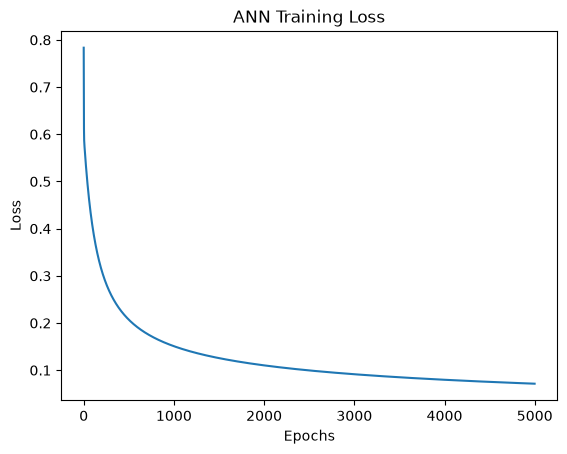

In [6]:
plt.plot(loss_history)
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("ANN Training Loss")
plt.show()

# Cell 7: Predict the classes

In [7]:
predictions = sigmoid(np.dot(X, weights) + bias)
predicted_classes = (predictions >= 0.5).astype(int)

print("Actual Classes:")
print(y.astype(int).flatten())

print("\nPredicted Classes:")
print(predicted_classes.flatten())

Actual Classes:
[0 0 0 0 1 1 1 1]

Predicted Classes:
[0 0 0 0 1 1 1 1]


# Cell 8: Test with a new input

In [8]:
study_hours = np.array([[4.5]])

probability = sigmoid(np.dot(study_hours, weights) + bias)
predicted_class = int(probability[0, 0] >= 0.5)

print("Study Hours:", study_hours[0, 0])
print("Pass Probability:", round(float(probability[0, 0]), 4))
print("Predicted Class:", "Pass" if predicted_class == 1 else "Fail")

Study Hours: 4.5
Pass Probability: 0.5411
Predicted Class: Pass


# Cell 9: Evaluate accuracy

In [9]:
accuracy = np.mean(predicted_classes == y.astype(int)) * 100

print("Training Accuracy:", accuracy, "%")

Training Accuracy: 100.0 %
